# 02 - Fragmentomic features

Each feature block, and whether it moves in the direction the literature
predicts.

In [1]:
import os, sys
sys.path.insert(0, os.path.abspath('../src'))
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from cfdna_insight.features import load_features, split_legacy_technical

FEATURES = '../results/features'

# split_legacy_technical moves chromosome entropy and coverage dispersion out
# of the technical block. They are copy-number readouts, and leaving them in
# the negative control makes it fire for biological reasons.
blocks = split_legacy_technical(load_features(FEATURES))

samples = pd.read_csv(os.path.join(FEATURES, 'samples_used.tsv'), sep='\t')
order = [s for s in samples['sample_id'] if s in blocks['size_summary'].index]
samples = samples.set_index('sample_id').loc[order].reset_index()
y = (samples['label'] == 'cancer').astype(int).to_numpy()

print(f'{len(order)} samples, {y.sum()} cancer, {len(y)-y.sum()} control')
{k: v.shape for k, v in blocks.items()}

[info] moved ['tech_chr_entropy', 'tech_coverage_cv'] from technical -> aneuploidy (they are copy-number readouts, not library metrics)
66 samples, 33 cancer, 33 control


{'coverage': (66, 550),
 'delfi': (66, 550),
 'motif': (66, 256),
 'size_hist': (66, 351),
 'size_summary': (66, 10),
 'technical': (66, 4),
 'window_arms': (66, 550),
 'aneuploidy': (66, 2)}

## Fragment size

The expected direction is that tumour cfDNA is shorter. Tested within
matched pairs, which removes age, sex, smoking, alcohol and batch.

In [2]:
from scipy.stats import wilcoxon

summ = blocks['size_summary'].reindex(order)
d = summ.join(samples.set_index('sample_id')[['pair_id', 'label']])
rows = []
for c in summ.columns:
    piv = d.pivot_table(index='pair_id', columns='label', values=c).dropna()
    if piv.empty or np.allclose(piv['cancer'] - piv['healthy'], 0):
        continue
    _, p = wilcoxon(piv['cancer'], piv['healthy'])
    rows.append({'feature': c,
                 'cancer_median': piv['cancer'].median(),
                 'control_median': piv['healthy'].median(),
                 'n_case_higher': int((piv['cancer'] > piv['healthy']).sum()),
                 'n_pairs': len(piv), 'p': p})
pd.DataFrame(rows).sort_values('p').round(4)

,feature,cancer_median,control_median,n_case_higher,n_pairs,p
8,periodicity_10bp,0.0093,0.0102,13,33,0.2719
9,mds,0.9500,0.9500,13,33,0.3669
6,frac_dinucleosomal,0.0000,0.0000,9,33,0.4265
2,size_iqr,22.0000,23.0000,11,33,0.4772
3,frac_below_150,0.1650,0.1717,13,33,0.4798
7,short_long_ratio_global,0.2068,0.2180,15,33,0.5483
1,size_mean,167.4443,166.9969,17,33,0.5965
4,frac_below_120,0.0254,0.0249,15,33,0.7376
5,frac_167_181,0.3251,0.3284,15,33,0.7644
0,size_median,168.0000,168.0000,14,33,0.9356


Nothing. No size feature differs between a case and its own matched
control, and the split is near 50/50 on every one of them.

## DELFI short/long profile

Rows are samples, columns 5 Mb windows in genome order. The within-sample
z-scoring removes any uniform shift by construction, so what to look for is
whether cancer rows are *more variable* along the genome.

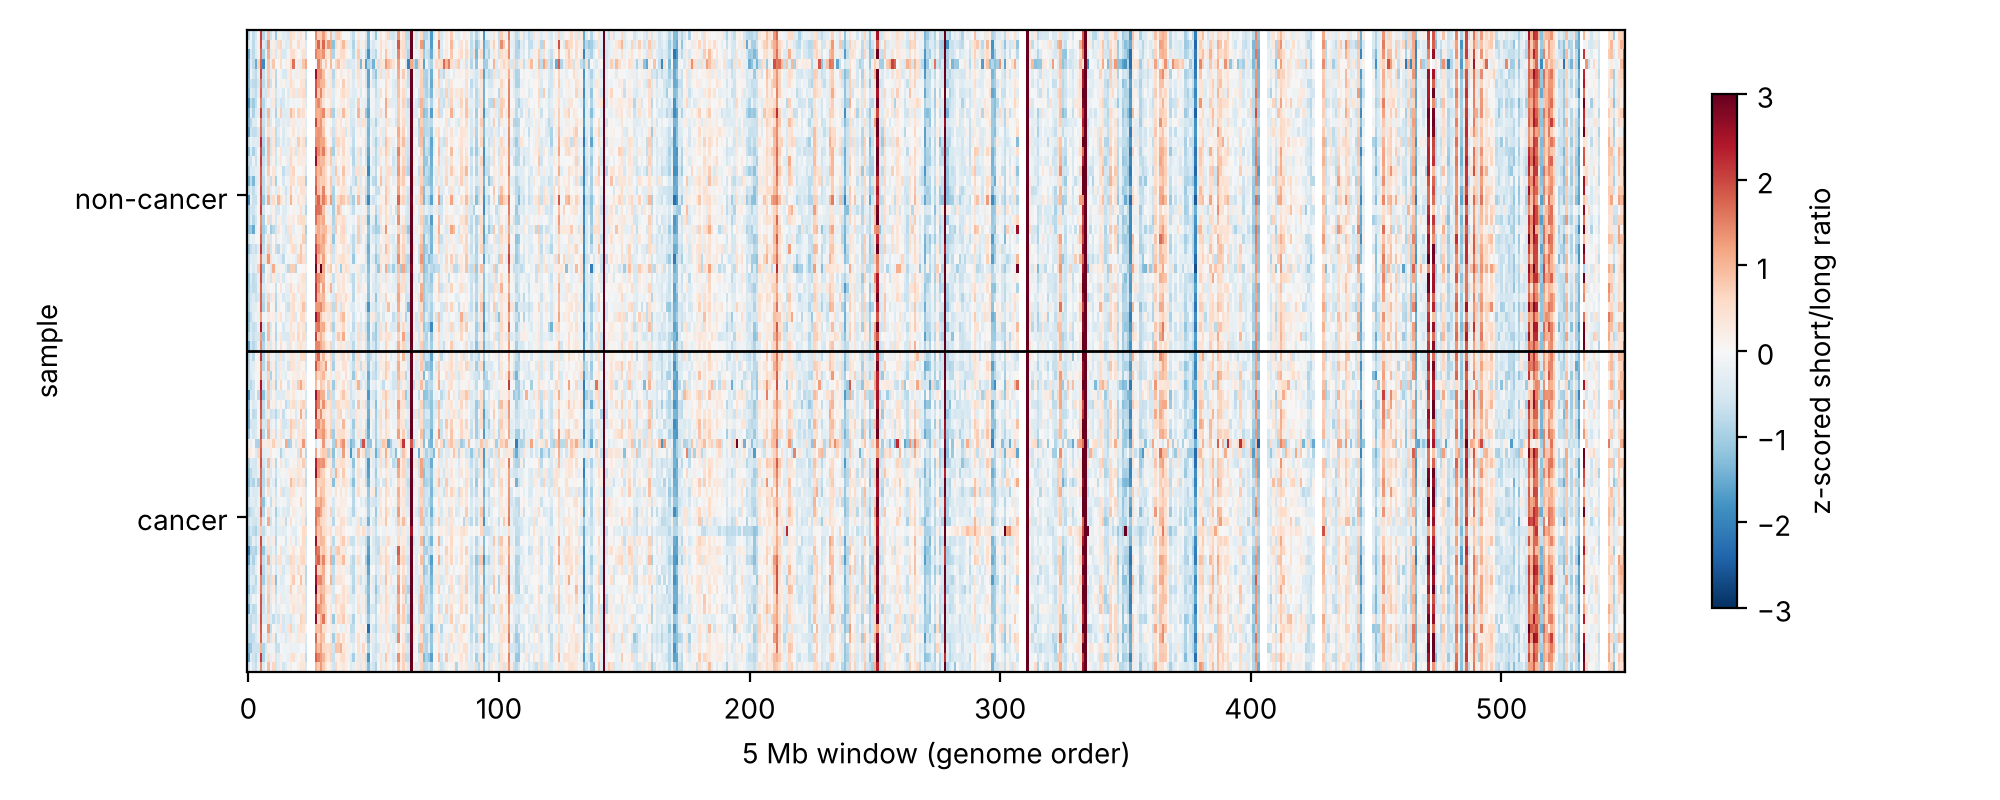

In [3]:
from cfdna_insight.plots import plot_delfi_heatmap
from IPython.display import Image
plot_delfi_heatmap(blocks['delfi'].reindex(order), y, '/tmp/delfi.png')
Image('/tmp/delfi.png')

In [4]:
from scipy.stats import mannwhitneyu
delfi = blocks['delfi'].reindex(order)
sd = delfi.std(axis=1)
u, p = mannwhitneyu(sd[y == 1], sd[y == 0])
print(f'profile variability: cancer {sd[y==1].median():.3f} vs '
      f'control {sd[y==0].median():.3f}, p = {p:.3g}')

profile variability: cancer 1.001 vs control 1.001, p = 0.412


## Aneuploidy proxies

`an_chr_entropy` is the normalised Shannon entropy of the per-chromosome
fragment proportions: how evenly fragments are spread across chromosomes.
Arm- and chromosome-scale copy-number change makes that spread less even.

Neither of these uses a reference panel, so neither can leak across CV
folds.

In [5]:
an = blocks['aneuploidy'].reindex(order)
d = an.join(samples.set_index('sample_id')[['pair_id', 'label']])
for c in an.columns:
    piv = d.pivot_table(index='pair_id', columns='label', values=c).dropna()
    _, p = wilcoxon(piv['cancer'], piv['healthy'])
    n_hi = int((piv['cancer'] > piv['healthy']).sum())
    print(f'{c:20s} case higher in {n_hi:2d}/{len(piv)} pairs   p = {p:.3g}')

an_chr_entropy       case higher in 30/33 pairs   p = 2.94e-07
an_coverage_cv       case higher in 23/33 pairs   p = 0.0551


In [6]:
fig, ax = plt.subplots(figsize=(5.5, 4.5))
piv = (an.join(samples.set_index('sample_id')[['pair_id', 'label']])
       .pivot_table(index='pair_id', columns='label',
                    values='an_chr_entropy').dropna())
for pid, r in piv.iterrows():
    up = r['cancer'] > r['healthy']
    ax.plot([0, 1], [r['healthy'], r['cancer']],
            color='#d1495b' if up else '#3b7dd8', alpha=.65, lw=1.2,
            marker='o', ms=3)
ax.set_xticks([0, 1]); ax.set_xticklabels(['matched control', 'case'])
ax.set_ylabel('chromosome entropy')
ax.set_title(f'{int((piv["cancer"]>piv["healthy"]).sum())}/{len(piv)} pairs rise', fontsize=10)
ax.spines[['top', 'right']].set_visible(False)
fig.tight_layout()
fig

<Figure size 550x450 with 1 Axes>

Each line is one matched pair. Red rises, blue falls.

## End motifs

4-mer at each fragment's 5' end. Reduced motif diversity in cancer is the
reported direction, attributed to altered nuclease activity. Notebook 03
tests whether that holds up here.

In [7]:
if 'motif' in blocks:
    mds = blocks['size_summary'].reindex(order)['mds']
    u, p = mannwhitneyu(mds[y == 1].dropna(), mds[y == 0].dropna())
    print(f'MDS: cancer {mds[y==1].median():.4f} vs control '
          f'{mds[y==0].median():.4f}, p = {p:.3g}')
    m = blocks['motif'].reindex(order)
    diff = (m[y == 1].mean() - m[y == 0].mean()).sort_values()
    print('\nmost shifted 4-mers:')
    print(pd.concat([diff.head(4), diff.tail(4)]).round(5))

MDS: cancer 0.9500 vs control 0.9500, p = 0.481

most shifted 4-mers:
motif_TAAA   -0.00046
motif_AAAA   -0.00042
motif_TATA   -0.00040
motif_TATT   -0.00039
motif_CAGG    0.00028
motif_CCAG    0.00042
motif_CCCA    0.00051
motif_CCTG    0.00055
dtype: float64
